# Maxi: ¿qué pasa con el ruido?

Objetivo: entender **qué fuente de ruido le hace más daño a nuestro circuito y por qué**, qué papel juega la arquitectura del chip (conectividad, un enlace o un qubit malo) y **si ZNE lo corrige**.

- **Estado**: el VQE de Fede `uccsd2_tap` (UCCSD con 2 repeticiones, 5 qubits) a **d = 2,4 Å**, en la zona estirada. Sin ruido le gana a CCSD con precisión química.
- **Ruido**: modelos de `qiskit_aer.noise` armados a mano (`src/noise.py`), para prender **una fuente por vez**, y el ruido calibrado de un chip real de IBM (`FakeFez`).
- **Medición**: siempre con shots (`measure_energy`, 1 M shots, σ ≈ 2,7 mHa). El ruido se simula con matriz densidad.

| fuente | qué modela | parámetro |
|---|---|---|
| ruido de compuerta de 2 qubits | despolarizante en cada `cz` | `p_2q` |
| ruido de compuerta de 1 qubit | despolarizante en cada `sx`, `x` | `p_1q` |
| decoherencia del qubit | relajación T1/T2 mientras dura cada compuerta | `t1_us` |
| lectura | probabilidad de leer el bit al revés | `readout` |
| un enlace malo | una `cz` entre dos qubits concretos mucho peor | `bad_pairs` |
| un qubit malo | un qubit con T1 corto | `bad_qubits` |

In [1]:
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
%matplotlib inline

# mismo namespace que el notebook final: todos los src/*.py juntos
for name in ["hamiltonian", "ansatz", "vqe", "measurement", "analysis", "pipeline", "noise"]:
    code = open(f"../src/{name}.py").read().split('if __name__ == "__main__":')[0]   # sin los bloques de prueba
    exec(code, globals())

SHOTS = 1_000_000
D = 2.4

def load_state(kind, d=D):
    pts = load_points(kind, "../results")
    problem, ansatz = prepare_point(d, kind)
    theta, _ = align_theta(problem, ansatz, kind, pts[d]["theta"], pts[d]["e_exact"])
    return {"kind": kind, "problem": problem, "ansatz": ansatz, "theta": theta, "e_exact": pts[d]["e_exact"]}

state = load_state("uccsd2_tap")
cheap = load_state("uccsd_tap")      # el ansatz más barato de Fede, para comparar
H = state["problem"]["hamiltonian"]
E0 = state["e_exact"]
E_MIX = mixed_state_energy(H)
print(f"E exacta del ansatz: {E0:.6f} Ha   FCI: {state['problem']['e_fci']:.6f}   CCSD: {state['problem']['e_ccsd']:.6f}")
print(f"E del estado totalmente mezclado (ruido máximo): {E_MIX:.6f} Ha  -> error máximo posible {1e3 * (E_MIX - E0):.0f} mHa")

def noisy_error(device, st=state, fold=1, seed=1):
    """Error (mHa) de la energía medida con ruido respecto de la exacta, y su σ."""
    r = measure_energy(st["ansatz"], st["theta"], st["problem"]["hamiltonian"], SHOTS, seed=seed, noise=device, fold=fold)
    return 1e3 * (r["energy"] - st["e_exact"]), 1e3 * r["sigma"]

E exacta del ansatz: -1.874652 Ha   FCI: -1.874652   CCSD: -1.905212
E del estado totalmente mezclado (ruido máximo): -1.082086 Ha  -> error máximo posible 793 mHa


## 1. Arquitectura: cuántas `cz` cuesta el circuito según la conectividad

En un chip real cada qubit solo hace `cz` con sus vecinos. Si el circuito necesita una `cz` entre qubits que no son vecinos, el transpilador agrega SWAPs (3 `cz` cada uno). Comparamos **en línea** (como IBM, aprox.) contra **todos con todos** (como iones atrapados).

In [2]:
rows = []
for st in (cheap, state):
    bound = st["ansatz"].assign_parameters(st["theta"])
    for conn in ("full", "line"):
        ops = transpile_for(bound, make_device(5, connectivity=conn)).count_ops()
        rows.append({"ansatz": st["kind"], "conectividad": conn, "cz": ops.get("cz", 0),
                     "compuertas de 1 qubit (sx, x)": ops.get("sx", 0) + ops.get("x", 0)})
fez_ops = transpile_for(state["ansatz"].assign_parameters(state["theta"]), backend_device("FakeFez")).count_ops()
rows.append({"ansatz": "uccsd2_tap", "conectividad": "FakeFez (heavy-hex)", "cz": fez_ops.get("cz", 0),
             "compuertas de 1 qubit (sx, x)": fez_ops.get("sx", 0) + fez_ops.get("x", 0)})
pd.DataFrame(rows)

,ansatz,conectividad,cz,"compuertas de 1 qubit (sx, x)"
0,uccsd_tap,full,170,233
1,uccsd_tap,line,428,737
2,uccsd2_tap,full,340,463
3,uccsd2_tap,line,868,1495
4,uccsd2_tap,FakeFez (heavy-hex),727,1190


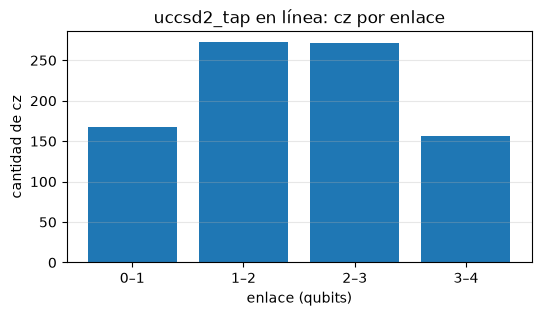

In [3]:
link_counts = two_qubit_gate_counts(state["ansatz"].assign_parameters(state["theta"]), make_device(5))
links = sorted(link_counts)
fig, ax = plt.subplots(figsize=(6, 3))
ax.bar([f"{i}–{j}" for i, j in links], [link_counts[l] for l in links])
ax.set_xlabel("enlace (qubits)")
ax.set_ylabel("cantidad de cz")
ax.set_title("uccsd2_tap en línea: cz por enlace")
ax.grid(alpha=0.3, axis="y")

## 2. Ruido de compuerta: ¿pesa más la `cz` o las de 1 qubit?

Barrido de la probabilidad de error, **una fuente por vez**. La línea punteada es la precisión química (1,6 mHa); arriba de todo está el estado totalmente mezclado.

56 s


,"cz, línea (uccsd2_tap, 868 cz)","cz, todos con todos (340 cz)","cz, línea, uccsd_tap (428 cz)","1 qubit, línea"
p = 1e-05,6.0 ± 2.6,1.4 ± 2.6,1.5 ± 2.6,8.3 ± 2.6
p = 3e-05,19.0 ± 2.6,6.2 ± 2.6,7.0 ± 2.6,25.8 ± 2.7
p = 0.0001,62.4 ± 2.7,23.1 ± 2.6,29.1 ± 2.6,83.0 ± 2.7
p = 0.0003,167.3 ± 2.8,70.5 ± 2.7,85.5 ± 2.7,219.1 ± 2.8
p = 0.001,435.4 ± 3.0,217.1 ± 2.8,253.3 ± 2.9,524.7 ± 3.0


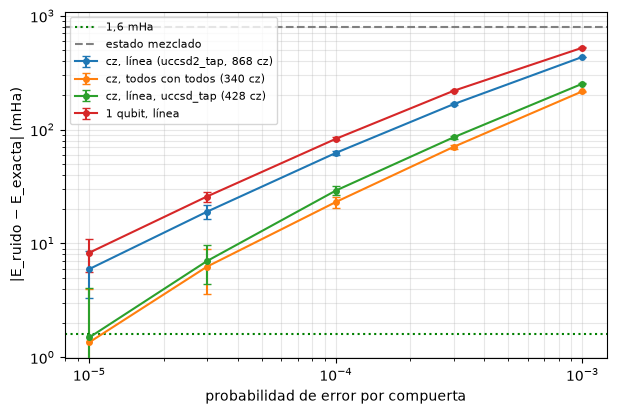

In [4]:
ps = [1e-5, 3e-5, 1e-4, 3e-4, 1e-3]
t0 = time.time()
sweeps = {
    "cz, línea (uccsd2_tap, 868 cz)": [noisy_error(make_device(5, p_2q=p)) for p in ps],
    "cz, todos con todos (340 cz)":   [noisy_error(make_device(5, p_2q=p, connectivity="full")) for p in ps],
    "cz, línea, uccsd_tap (428 cz)":  [noisy_error(make_device(5, p_2q=p), st=cheap) for p in ps],
    "1 qubit, línea":                 [noisy_error(make_device(5, p_1q=p)) for p in ps],
}
print(f"{time.time() - t0:.0f} s")

fig, ax = plt.subplots(figsize=(7, 4.5))
for label, vals in sweeps.items():
    err = np.array([v[0] for v in vals]); sig = np.array([v[1] for v in vals])
    ax.errorbar(ps, np.abs(err), yerr=sig, fmt="o-", ms=4, capsize=3, label=label)
ax.axhline(1.6, color="green", ls=":", label="1,6 mHa")
ax.axhline(1e3 * (E_MIX - E0), color="gray", ls="--", label="estado mezclado")
ax.set_xscale("log"); ax.set_yscale("log")
ax.set_xlabel("probabilidad de error por compuerta")
ax.set_ylabel("|E_ruido − E_exacta| (mHa)")
ax.legend(fontsize=8); ax.grid(alpha=0.3, which="both")
pd.DataFrame({k: [f"{v[0]:.1f} ± {v[1]:.1f}" for v in vals] for k, vals in sweeps.items()}, index=[f"p = {p:g}" for p in ps])

**Regla práctica**: con poco ruido, el error crece como (cantidad de compuertas) × p × (algo del orden de la brecha al estado mezclado). Por eso lo que importa es **p × número de `cz`**: bajar la cantidad de `cz` (mejor conectividad, ansatz más barato) rinde tanto como mejorar la compuerta.

Text(0.5, 1.0, 'las tres curvas colapsan en una')

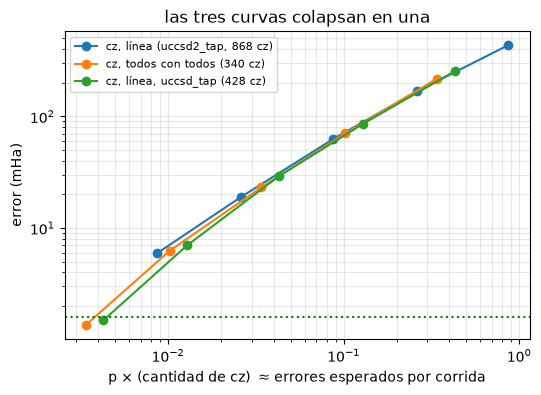

In [5]:
lin = [(label, n) for label, n in (("cz, línea (uccsd2_tap, 868 cz)", 868), ("cz, todos con todos (340 cz)", 340), ("cz, línea, uccsd_tap (428 cz)", 428))]
fig, ax = plt.subplots(figsize=(6, 4))
for label, n in lin:
    err = np.array([v[0] for v in sweeps[label]])
    ax.plot(np.array(ps) * n, err, "o-", label=label)
ax.axhline(1.6, color="green", ls=":")
ax.set_xscale("log"); ax.set_yscale("log")
ax.set_xlabel("p × (cantidad de cz)  ≈ errores esperados por corrida")
ax.set_ylabel("error (mHa)")
ax.legend(fontsize=8); ax.grid(alpha=0.3, which="both")
ax.set_title("las tres curvas colapsan en una")

## 3. Ruido del qubit: decoherencia (T1/T2) y lectura

35 s


,T1 (µs),error relajación (mHa),lectura,error lectura (mHa)
0,20,841.8 ± 3.1,0.1%,5.3 ± 2.6
1,50,772.3 ± 3.1,0.5%,30.8 ± 2.6
2,100,600.5 ± 3.0,1.0%,59.4 ± 2.7
3,200,391.1 ± 2.9,2.0%,116.9 ± 2.7
4,500,182.2 ± 2.8,5.0%,265.8 ± 2.8


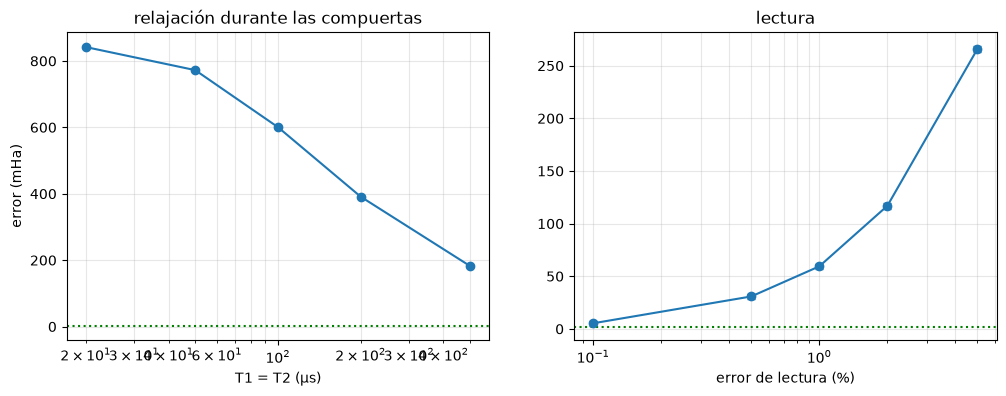

In [6]:
t1s = [20, 50, 100, 200, 500]
ros = [1e-3, 5e-3, 1e-2, 2e-2, 5e-2]
t0 = time.time()
relax = [noisy_error(make_device(5, t1_us=t)) for t in t1s]
readout = [noisy_error(make_device(5, readout=r)) for r in ros]
print(f"{time.time() - t0:.0f} s")

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].errorbar(t1s, [v[0] for v in relax], yerr=[v[1] for v in relax], fmt="o-", capsize=3)
axes[0].set_xscale("log"); axes[0].set_xlabel("T1 = T2 (µs)"); axes[0].set_ylabel("error (mHa)")
axes[0].set_title("relajación durante las compuertas")
axes[1].errorbar(np.array(ros) * 100, [v[0] for v in readout], yerr=[v[1] for v in readout], fmt="o-", capsize=3)
axes[1].set_xscale("log"); axes[1].set_xlabel("error de lectura (%)"); axes[1].set_title("lectura")
for a in axes:
    a.axhline(1.6, color="green", ls=":"); a.grid(alpha=0.3, which="both")
pd.DataFrame({"T1 (µs)": t1s, "error relajación (mHa)": [f"{v[0]:.1f} ± {v[1]:.1f}" for v in relax],
              "lectura": [f"{r:.1%}" for r in ros], "error lectura (mHa)": [f"{v[0]:.1f} ± {v[1]:.1f}" for v in readout]})

Ojo: el modelo aplica la relajación **solo mientras dura cada compuerta** (36 ns las de 1 qubit, 68 ns la `cz`), no mientras un qubit espera sin hacer nada. En un chip real los qubits ociosos también decaen, así que estos números son optimistas para T1/T2.

## 4. Un enlace malo o un qubit malo

Todo ideal salvo **un** elemento:
- **enlace malo**: una sola `cz` (entre dos qubits vecinos) con 0,1 % de error;
- **qubit malo**: un solo qubit con T1 = T2 = 10 µs.

¿Importa **dónde** está el elemento malo? Si el daño depende de cuántas compuertas lo usan, el circuito es más sensible en los enlaces más cargados (gráfico de la sección 1).

25 s


,enlace,cz,error (mHa),mHa por cz
0,0–1,168,113.8 ± 2.7,0.677572
1,1–2,272,170.2 ± 2.8,0.625570
2,2–3,271,174.2 ± 2.8,0.642956
3,3–4,157,111.6 ± 2.7,0.710648


,qubit,cz en las que participa,error (mHa)
0,0,168,270.9 ± 2.9
1,1,440,493.5 ± 3.0
2,2,543,577.8 ± 3.0
3,3,428,514.1 ± 3.0
4,4,157,250.2 ± 2.9


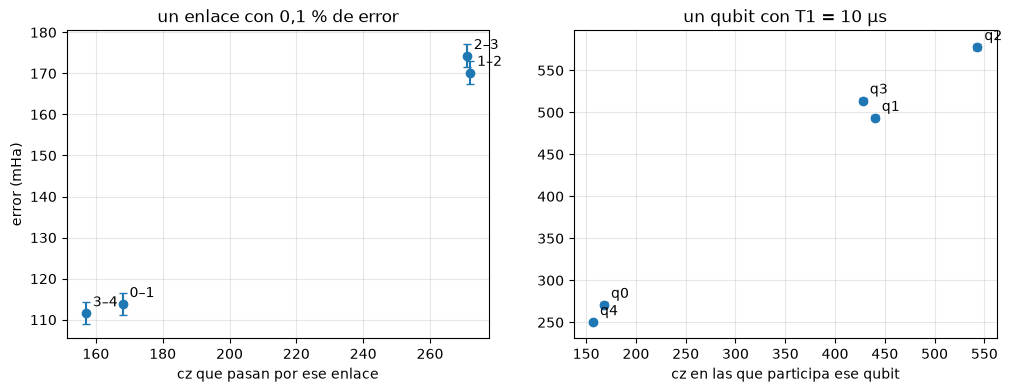

In [7]:
t0 = time.time()
bad_link = {l: noisy_error(make_device(5, bad_pairs={l: 1e-3})) for l in links}
bad_qubit = {q: noisy_error(make_device(5, bad_qubits={q: 10})) for q in range(5)}
print(f"{time.time() - t0:.0f} s")

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
x = [link_counts[l] for l in links]
axes[0].errorbar(x, [bad_link[l][0] for l in links], yerr=[bad_link[l][1] for l in links], fmt="o", capsize=3)
for l, xi in zip(links, x):
    axes[0].annotate(f"{l[0]}–{l[1]}", (xi, bad_link[l][0]), textcoords="offset points", xytext=(5, 5))
axes[0].set_xlabel("cz que pasan por ese enlace"); axes[0].set_ylabel("error (mHa)")
axes[0].set_title("un enlace con 0,1 % de error")
qubit_load = {q: sum(n for l, n in link_counts.items() if q in l) for q in range(5)}
axes[1].errorbar([qubit_load[q] for q in range(5)], [bad_qubit[q][0] for q in range(5)],
                 yerr=[bad_qubit[q][1] for q in range(5)], fmt="o", capsize=3)
for q in range(5):
    axes[1].annotate(f"q{q}", (qubit_load[q], bad_qubit[q][0]), textcoords="offset points", xytext=(5, 5))
axes[1].set_xlabel("cz en las que participa ese qubit"); axes[1].set_title("un qubit con T1 = 10 µs")
for a in axes:
    a.grid(alpha=0.3)
display(pd.DataFrame([{"enlace": f"{l[0]}–{l[1]}", "cz": link_counts[l], "error (mHa)": f"{bad_link[l][0]:.1f} ± {bad_link[l][1]:.1f}",
                       "mHa por cz": bad_link[l][0] / link_counts[l]} for l in links]))
pd.DataFrame([{"qubit": q, "cz en las que participa": qubit_load[q], "error (mHa)": f"{bad_qubit[q][0]:.1f} ± {bad_qubit[q][1]:.1f}"} for q in range(5)])

## 5. ZNE: extrapolación a ruido cero

Se mide con cada `cz` repetida **1, 3 y 5 veces** (`cz`, `cz·cz†·cz`, ...: misma operación, ~3× y ~5× el ruido de la `cz`) y se extrapola a ruido 0:
- **lineal**: recta por los 3 puntos;
- **Richardson**: parábola que pasa exacto por los 3 puntos;
- **exponencial**: $E(\lambda) = E_\text{mezcla} + A\,e^{-c\lambda}$, porque el ruido despolarizante lleva la energía hacia la del estado mezclado, que conocemos.

La σ de la extrapolación se propaga desde las σ de cada medición: ZNE **cuesta shots** (3 mediciones y σ amplificada).

Lo que se espera: plegar solo escala el ruido de las `cz`, así que **ZNE debería corregir el ruido de compuerta de 2 qubits, en parte la relajación durante las `cz`, y nada de la lectura ni de las compuertas de 1 qubit.**

In [8]:
devices = [
    make_device(5, p_2q=1e-4),
    make_device(5, p_2q=3e-4),
    make_device(5, p_2q=1e-3),
    make_device(5, p_2q=1e-4, connectivity="full"),
    make_device(5, p_1q=1e-3),
    make_device(5, t1_us=50),
    make_device(5, readout=1e-2),
    make_device(5, p_2q=1e-4, p_1q=1e-5, t1_us=200, readout=5e-3, label="combinado: p2q=1e-4, p1q=1e-5, T1=200µs, lectura 0,5% (line)"),
]
t0 = time.time()
zne_results = {dev["label"]: zne(state["ansatz"], state["theta"], H, SHOTS, dev) for dev in devices}
print(f"{time.time() - t0:.0f} s")

def fmt(v):
    return f"{1e3 * (v['energy'] - E0):+.1f} ± {1e3 * v['sigma']:.1f}"
pd.DataFrame([{"ruido": label, "sin mitigar": fmt(z["noisy"]),
               **{f"ZNE {m}": fmt(v) for m, v in z["extrapolated"].items()}}
              for label, z in zne_results.items()]).set_index("ruido")

119 s


,sin mitigar,ZNE linear,ZNE richardson,ZNE exponential
ruido,,,,
p2q=0.0001 (line),+58.8 ± 2.7,+10.8 ± 3.3,-1.6 ± 6.2,-3.0 ± 3.8
p2q=0.0003 (line),+169.0 ± 2.8,+84.2 ± 3.4,+23.7 ± 6.5,-10.3 ± 6.1
p2q=0.001 (line),+434.8 ± 3.0,+383.5 ± 3.6,+214.5 ± 6.8,-143.4 ± 155.4
p2q=0.0001 (full),+26.4 ± 2.7,+4.6 ± 3.2,+3.1 ± 6.1,+2.3 ± 3.4
p1q=0.001 (line),+528.6 ± 3.0,+524.9 ± 3.6,+539.5 ± 6.9,+524.9 ± 3.7
T1=50µs (line),+776.5 ± 3.1,+765.6 ± 3.7,+721.5 ± 7.0,+nan ± nan
readout=0.01 (line),+59.3 ± 2.7,+59.5 ± 3.2,+59.5 ± 6.1,+59.5 ± 3.2
"combinado: p2q=1e-4, p1q=1e-5, T1=200µs, lectura 0,5% (line)",+440.5 ± 3.0,+376.2 ± 3.6,+263.6 ± 6.8,-5256.7 ± 1758.6


Valores: **error respecto de la energía exacta, en mHa** (± σ). Un buen resultado es compatible con 0 dentro de σ.

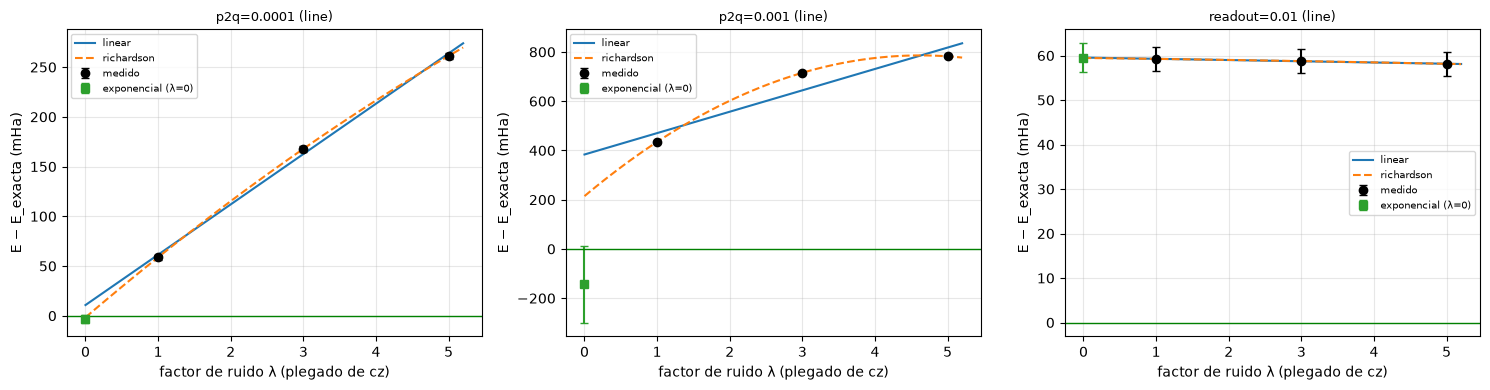

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
lam = np.linspace(0, 5.2, 100)
for ax, label in zip(axes, [devices[0]["label"], devices[2]["label"], devices[6]["label"]]):
    z = zne_results[label]
    sc = np.array(z["scales"]); e = 1e3 * (np.array(z["energies"]) - E0); s = 1e3 * np.array(z["sigmas"])
    ax.errorbar(sc, e, yerr=s, fmt="o", capsize=3, color="black", label="medido")
    for m, style in (("linear", "-"), ("richardson", "--")):
        deg = 1 if m == "linear" else len(sc) - 1
        ax.plot(lam, np.polyval(np.polyfit(sc, e, deg), lam), style, label=m)
    ex = z["extrapolated"]["exponential"]
    ax.errorbar([0], [1e3 * (ex["energy"] - E0)], yerr=[1e3 * ex["sigma"]], fmt="s", capsize=3, label="exponencial (λ=0)")
    ax.axhline(0, color="green", lw=1)
    ax.set_xlabel("factor de ruido λ (plegado de cz)"); ax.set_ylabel("E − E_exacta (mHa)")
    ax.set_title(label, fontsize=9); ax.legend(fontsize=7); ax.grid(alpha=0.3)
fig.tight_layout()

## 6. Un chip real: `FakeFez`

Ruido calibrado de `ibm_fez` (Heron, conectividad heavy-hex): errores de `cz`, de 1 qubit, T1/T2 y lectura de cada qubit, todos juntos. El transpilador elige en qué qubits físicos poner el circuito.

In [10]:
t0 = time.time()
fez = backend_device("FakeFez")
z_fez = zne(state["ansatz"], state["theta"], H, SHOTS, fez)
print(f"{time.time() - t0:.0f} s")
print(f"sin mitigar: {fmt(z_fez['noisy'])} mHa")
for m, v in z_fez["extrapolated"].items():
    print(f"ZNE {m:12s}: {fmt(v)} mHa")
print(f"error máximo posible (estado mezclado): {1e3 * (E_MIX - E0):.0f} mHa")

174 s
sin mitigar: +774.8 ± 3.1 mHa
ZNE linear      : +767.7 ± 3.7 mHa
ZNE richardson  : +759.6 ± 7.0 mHa
ZNE exponential : +nan ± nan mHa
error máximo posible (estado mezclado): 793 mHa


## Conclusiones

**1. La arquitectura decide cuántas compuertas hay, y eso decide casi todo.** El mismo estado necesita 868 `cz` y 1495 compuertas de 1 qubit con conectividad en línea, 727 `cz` en el heavy-hex de Fez y solo 340 `cz` y 463 de 1 qubit con todos-con-todos. Con el mismo error por `cz` (0,01 %), el error de energía baja de 62 a 23 mHa solo por la conectividad.

**2. El error escala con p × (cantidad de `cz`).** Las tres curvas del barrido de `cz` caen sobre una sola cuando se grafica contra p × N_cz. Bajar las `cz` a la mitad rinde lo mismo que una compuerta el doble de buena. Mientras p × N_cz ≪ 1 el error es aproximadamente lineal; cuando se acerca a 1 la energía satura en la del estado mezclado (793 mHa por encima).

**3. Las compuertas de 1 qubit no son despreciables.** Con el mismo p hacen *más* daño que la `cz` (525 contra 435 mHa con p = 0,1 %) porque hay 1495. En hardware real su error es ~10 veces menor que el de la `cz`, pero no hay que ignorarlas.

**4. La decoherencia (T1/T2) es la fuente dominante para este circuito.** Aun con T1 = T2 = 500 µs el error es de 182 mHa, y con T1 = 200 µs (típico de Heron) es de 391 mHa. El circuito es demasiado largo: el qubit 2 participa en 543 `cz`, unos 37 µs solo en compuertas de 2 qubits. Y el modelo es optimista, porque no cuenta la relajación de los qubits ociosos.

**5. Un enlace o un qubit malo pesan según cuánto se usan.** Una `cz` con 0,1 % de error en un enlace cuesta ~0,65 mHa por cada `cz` que pasa por él: 112–114 mHa en los extremos (157–168 `cz`) contra 170–174 mHa en los enlaces centrales (271–272 `cz`). Con un qubit malo pasa lo mismo: 250–270 mHa en los extremos, 494–578 mHa en los del medio. En un chip real conviene poner los qubits más cargados sobre los mejores qubits físicos (eso es elegir el *layout*).

**6. ZNE funciona solo contra el ruido que escala, y solo si no está saturado.**
- `cz` con 0,01 % (p × N_cz ≈ 0,09): de 58,8 mHa a **−1,6 ± 6,2 (Richardson) y −3,0 ± 3,8 (exponencial)**, compatible con 0. Con todos-con-todos: de 26,4 a +2,3 ± 3,4.
- `cz` con 0,03 % (p × N_cz ≈ 0,26): corrige en parte (exponencial −10 ± 6 mHa).
- `cz` con 0,1 % (p × N_cz ≈ 0,9): falla; el ruido ya saturó y no queda señal para extrapolar.
- Lectura, compuertas de 1 qubit y T1/T2: **ZNE no cambia nada**, porque plegar las `cz` no escala esos errores. La lectura se corrige con otra técnica (mitigación de lectura, por ejemplo invertir la matriz de confusión).
- La extrapolación cuesta: 3 veces los shots y σ amplificada (×2,3 con Richardson).

**7. FakeFez: hoy no se puede.** Con el ruido calibrado de `ibm_fez` el error es de 775 mHa sobre un máximo de 793; el estado está prácticamente mezclado y ZNE no lo recupera.

**Qué haría falta para que se banque el ruido**: llevar p × N_cz por debajo de ~0,1 y acortar el circuito frente a T1. En concreto: un ansatz con muchas menos `cz` (por ejemplo podar las excitaciones con θ chico, o `uccsd_tap`, con 170 `cz` en todos-con-todos), elegir bien el layout, ZNE para el ruido de las `cz` y mitigación de lectura aparte.